# Task 14 — Explain Every Person's Risk

## Objective (from the task instructions)
Score all 430 active employees with the versioned Task 13 model, assign the company's risk bands, use SHAP to identify each person's top three drivers, translate those drivers into plain-English reasons, match the supplied sample output format, and export the 430-row report. Review ten rows for clarity and fairness.

## Source and implementation classification
- **Task requirement:** 430 scores, risk bands, three reasons per employee, SHAP summary, 10-row review sample, exact sample output schema, and human-review note.
- **Reused project components:** Task 2 `build_features()`; Task 4 `risk_bands()`; Task 13 `attrition-v2` calibrated XGBoost artifact and metadata.
- **Additional implementation decisions (documented, not presented as task requirements):** TreeSHAP is run on each of the five XGBoost estimators inside the calibrated ensemble; one-hot encoded contributions are summed back to the original 45 input features; a seeded 40-row background sample is drawn from the scoring cohort; the top three positive grouped contributions are rendered as cautious association-based sentences. See the report for the explanation-scale limitation.

**Important:** The final risk score is the calibrated ensemble probability. TreeSHAP values here explain the underlying raw XGBoost estimators before sigmoid calibration; they are useful driver explanations but are not an exact additive decomposition of the calibrated probability. Reasons are not causes and must be reviewed by a human.

## 1. Load inputs and existing project components

Expected repository files:
- `data/attrition_scoring_2026.csv`
- `data/attendance_monthly_features.csv`
- `data/payroll_monthly_features.csv`
- `models/attrition/attrition-v2/model.joblib`
- `models/attrition/attrition-v2/metadata.json`
- `src/features/build_features.py`
- `05_Starter/cortexhr_helpers.py`

The sample output is `data/sample_attrition_risk.csv` (adjust `DATA_DIR` only if the project stores it elsewhere).

In [1]:
%pip install shap


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install xgboost


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import json, sys, warnings
import numpy as np
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt
import sklearn
from sklearn.exceptions import InconsistentVersionWarning

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
MODEL_DIR = ROOT / "models" / "attrition" / "attrition-v2"
REPORTS_DIR = ROOT / "reports"
EVIDENCE_DIR = ROOT / "evidence"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
if str(ROOT / "05_Starter") not in sys.path:
    sys.path.insert(0, str(ROOT / "05_Starter"))

from src.features.build_features import build_features
from cortexhr_helpers import risk_bands

SCORING_PATH = DATA_DIR / "attrition_scoring_2026.csv"
ATTENDANCE_PATH = DATA_DIR / "attendance_monthly_features.csv"
PAYROLL_PATH = DATA_DIR / "payroll_monthly_features.csv"
SAMPLE_PATH = DATA_DIR / "sample_attrition_risk.csv"
MODEL_PATH = MODEL_DIR / "model.joblib"
METADATA_PATH = MODEL_DIR / "metadata.json"

required_paths = [SCORING_PATH, ATTENDANCE_PATH, PAYROLL_PATH, SAMPLE_PATH, MODEL_PATH, METADATA_PATH]
missing_paths = [str(p) for p in required_paths if not p.exists()]
if missing_paths:
    raise FileNotFoundError(f"Missing required inputs: {missing_paths}")

with open(METADATA_PATH, encoding="utf-8") as f:
    metadata = json.load(f)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", InconsistentVersionWarning)
    model = joblib.load(MODEL_PATH)
for warning in caught:
    print("MODEL COMPATIBILITY WARNING:", str(warning.message))

print("scikit-learn runtime:", sklearn.__version__)
print("Model version:", metadata["version"])
print("SHAP version:", shap.__version__)

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


scikit-learn runtime: 1.9.1
Model version: attrition-v2
SHAP version: 0.54.1


## 2. Reconstruct the Task 13 model inputs

The scoring CSV contains 34 source columns, while the model metadata requires 45 predictors. Do not invent or manually fill those missing predictors. Reuse the existing Task 2 `build_features()` function with the supplied monthly attendance and payroll files. That function aggregates records only up to each employee snapshot month and creates the same engineered columns used for training.

In [4]:
scoring = pd.read_csv(SCORING_PATH)
attendance = pd.read_csv(ATTENDANCE_PATH)
payroll = pd.read_csv(PAYROLL_PATH)
sample = pd.read_csv(SAMPLE_PATH)

features = build_features(scoring, attendance, payroll)
model_features = metadata["features"]
missing_features = [c for c in model_features if c not in features.columns]
if missing_features:
    raise ValueError(f"Task 13 model features are missing after Task 2 feature engineering: {missing_features}")

X = features[model_features].copy()
if len(X) != 430 or scoring["employee_id"].nunique() != 430:
    raise ValueError(f"Expected 430 unique active employees; found {len(X)} rows and {scoring.employee_id.nunique()} unique IDs.")
if len(sample.columns) != 11:
    raise ValueError("Unexpected sample schema; inspect sample_attrition_risk.csv before proceeding.")

print("Scoring rows:", len(X))
print("Model predictors:", X.shape[1])
print("Missing required model features:", missing_features)
print("Scoring date:", pd.to_datetime(scoring["observation_date"]).dt.date.unique())

Scoring rows: 430
Model predictors: 45
Missing required model features: []
Scoring date: [datetime.date(2026, 9, 30)]


## 3. Score all 430 employees and apply the company's risk bands

Use the calibrated `predict_proba` output for the final `risk_score_12m`. Risk bands come directly from the supplied Task 4 `risk_bands()` helper. No new thresholds are introduced.

In [5]:
risk_scores = model.predict_proba(X)[:, 1]
bands = risk_bands(risk_scores)

print("Scored:", len(risk_scores))
print("Score range:", float(risk_scores.min()), "to", float(risk_scores.max()))
print("Risk-band counts:")
print(pd.Series(bands).value_counts().reindex(["High", "Medium", "Low"]))

Scored: 430
Score range: 0.025893932591679547 to 0.42438134377698605
Risk-band counts:
High       43
Medium     86
Low       301
Name: count, dtype: int64


## 4. SHAP explanations for the five XGBoost estimators

The saved artifact is a `CalibratedClassifierCV` containing five fitted XGBoost pipelines. TreeSHAP is calculated separately for each underlying XGBoost estimator. Since the five fold preprocessors can produce slightly different one-hot columns, encoded contributions are mapped by their original source feature and summed into the 45 original feature groups.

**Additional decision:** use 40 scoring-cohort rows sampled with `random_state=42` as the interventional SHAP background. This makes explanations relative to the current scoring cohort because the original training dataset is not an input to Task 14.

**Scope limitation:** these SHAP contributions explain the raw XGBoost estimators before their sigmoid calibration. The final reported probability is the calibrated ensemble output. Do not describe SHAP values as an exact additive decomposition of the final calibrated probability.

In [6]:
if not hasattr(model, "calibrated_classifiers_"):
    raise TypeError("Expected the Task 13 CalibratedClassifierCV artifact.")
if len(model.calibrated_classifiers_) != 5:
    raise ValueError(f"Expected five calibrated fold estimators; found {len(model.calibrated_classifiers_)}.")

rng = np.random.default_rng(42)
background_idx = rng.choice(len(X), size=min(40, len(X)), replace=False)
grouped_shap_by_fold = []

for fold_no, calibrated in enumerate(model.calibrated_classifiers_, start=1):
    estimator = calibrated.estimator
    prep = estimator.named_steps["prep"]
    tree_model = estimator.named_steps["model"]

    transformed_X = prep.transform(X)
    transformed_background = prep.transform(X.iloc[background_idx])
    encoded_names = prep.get_feature_names_out().tolist()

    explainer = shap.TreeExplainer(
        tree_model,
        data=transformed_background,
        feature_perturbation="interventional",
        model_output="probability",
    )
    shap_values = np.asarray(explainer.shap_values(transformed_X))

    grouped = np.zeros((len(X), len(model_features)), dtype=float)
    feature_position = {name: idx for idx, name in enumerate(model_features)}

    for encoded_idx, encoded_name in enumerate(encoded_names):
        source_name = encoded_name.split("__", 1)[-1]
        original_name = next(
            (name for name in model_features
             if source_name == name or source_name.startswith(name + "_")),
            None,
        )
        if original_name is None:
            raise ValueError(f"Could not map transformed SHAP feature: {encoded_name}")
        grouped[:, feature_position[original_name]] += shap_values[:, encoded_idx]

    grouped_shap_by_fold.append(grouped)
    print(f"Fold {fold_no}: {shap_values.shape[1]} transformed features explained.")

grouped_shap = np.mean(np.stack(grouped_shap_by_fold), axis=0)
assert grouped_shap.shape == (len(X), len(model_features))
print("Grouped SHAP shape:", grouped_shap.shape)

Fold 1: 144 transformed features explained.
Fold 2: 145 transformed features explained.
Fold 3: 144 transformed features explained.
Fold 4: 144 transformed features explained.
Fold 5: 145 transformed features explained.
Grouped SHAP shape: (430, 45)


## 5. Convert each employee's top three positive drivers into plain English

Only positive grouped SHAP contributions are selected because the output asks for reasons that pushed the estimate upward. Wording deliberately says the feature **contributed to the model estimate**; it does not claim that the feature caused an employee to leave.

The sentence templates and feature labels below are additional presentation choices. They are documented so they can be reviewed or changed without changing the model.

In [7]:
FEATURE_LABELS = {
    "last_engagement_score": "Engagement score",
    "manager_changes_12m": "Manager changes in the last 12 months",
    "tenure_months": "Tenure",
    "comp_ratio": "Pay relative to role midpoint",
    "wfh_share_3m": "Work-from-home share",
    "commute_distance_km": "Commute distance",
    "last_performance_rating": "Last performance rating",
    "late_count": "Historical late arrivals",
    "attendance_rate": "Historical attendance rate",
    "avg_hours_worked_3m": "Average hours worked",
    "department_id": "Department",
    "role_id": "Role",
    "job_level": "Job level",
    "work_mode": "Work arrangement",
    "work_location": "Work location",
    "employment_type": "Employment type",
    "highest_education": "Education level",
    "total_experience_years": "Total work experience",
    "previous_employers_count": "Previous employer count",
    "months_since_last_raise": "Months since last raise",
    "months_since_last_promotion": "Months since last promotion",
    "attendance_rate_3m": "Recent attendance rate",
    "avg_overtime_hours_per_month_3m": "Recent average monthly overtime",
    "avg_hours_worked_3m": "Recent average hours worked",
    "unpaid_leave_days_6m": "Unpaid leave days in the last six months",
    "paid_leave_days_6m": "Paid leave days in the last six months",
    "dept_attrition_rate_prior_12m": "Historical department attrition rate",
    "attendance_gap": "Recent attendance gap",
    "average_overtime": "Historical average overtime",
    "unpaid_absence_days": "Historical unpaid absence days",
    "average_monthly_salary": "Average monthly fixed pay",
    "unpaid_payroll_days": "Historical unpaid payroll days",
    "average_overtime_pay": "Average overtime pay",
    "tenure_years": "Tenure in years",
    "raise_overdue": "Raise overdue indicator",
    "unpaid_per_month": "Average unpaid leave days per month",
    "overtime_load": "Recent monthly overtime load",
    "tenure": "Tenure in months",
    "months_since_last_revision": "Months since last pay revision",
}

def format_feature_value(feature, value):
    if pd.isna(value):
        return "not recorded"
    if feature in {"last_engagement_score", "last_performance_rating"}:
        return f"{float(value):.1f}/5"
    if feature in {"attendance_rate", "attendance_rate_3m", "wfh_share_3m"}:
        return f"{float(value):.0%}"
    if feature in {"annual_fixed_pay", "average_monthly_salary", "average_overtime_pay"}:
        return f"₹{float(value):,.0f}"
    if feature == "commute_distance_km":
        return f"{float(value):.1f} km"
    if feature == "comp_ratio":
        return f"{float(value):.2f}x"
    if feature == "raise_overdue":
        return "yes" if bool(value) else "no"
    if feature in {"tenure_years", "total_experience_years"}:
        return f"{float(value):.1f} years"
    if feature in {"avg_overtime_hours_per_month_3m", "avg_hours_worked_3m", "average_overtime", "overtime_load"}:
        return f"{float(value):.1f} hours"
    if feature == "unpaid_per_month":
        return f"{float(value):.1f} days/month"
    if isinstance(value, str):
        return value
    if isinstance(value, (int, float, np.integer, np.floating)):
        return f"{float(value):.1f}"
    return str(value)

reason_rows = []
for row_idx in range(len(X)):
    order = np.argsort(-grouped_shap[row_idx])
    top_positive = [j for j in order if grouped_shap[row_idx, j] > 0][:3]
    if len(top_positive) != 3:
        raise ValueError(f"Fewer than three positive SHAP drivers for row {row_idx}.")
    row_reasons = []
    for feature_idx in top_positive:
        feature = model_features[feature_idx]
        label = FEATURE_LABELS.get(feature, feature.replace("_", " ").capitalize())
        value = format_feature_value(feature, features.iloc[row_idx][feature])
        if feature in {"department_id", "role_id", "work_mode", "work_location", "employment_type", "highest_education"}:
            reason = f"{label} ({value}) pushed the model estimate upward."
        else:
            reason = f"{label} ({value}) contributed to a higher model estimate."
        row_reasons.append(reason)
    reason_rows.append(row_reasons)

assert all(len(row) == 3 for row in reason_rows)
print("Three reasons generated for every employee.")

Three reasons generated for every employee.


## 6. Export the 430-row report and 10-row review sample

The output columns and order are copied from `sample_attrition_risk.csv`. `risk_score_12m` is rounded to three decimals for consistency with the sample display; risk bands are calculated from the unrounded probabilities.

In [8]:
model_note = (
    "attrition-v2 calibrated XGBoost. SHAP reasons describe contributions from the underlying "
    "raw XGBoost models; they are model associations, not causes. Human review required. "
    "Risk bands follow the company top-10%/next-20% rule."
)

result = pd.DataFrame({
    "prediction_id": [f"AR-{i+1:04d}" for i in range(len(scoring))],
    "employee_id": scoring["employee_id"].astype(str),
    "department_id": scoring["department_id"],
    "as_of_date": pd.to_datetime(scoring["observation_date"]).dt.strftime("%Y-%m-%d"),
    "risk_score_12m": np.round(risk_scores, 3),
    "risk_band": bands,
    "top_reason_1": [r[0] for r in reason_rows],
    "top_reason_2": [r[1] for r in reason_rows],
    "top_reason_3": [r[2] for r in reason_rows],
    "model_version": metadata["version"],
    "model_note": model_note,
})

# Validate the exact sample schema before export.
if result.columns.tolist() != sample.columns.tolist():
    raise ValueError(f"Output schema mismatch. Expected {sample.columns.tolist()}, got {result.columns.tolist()}")
if len(result) != 430 or result["employee_id"].nunique() != 430:
    raise ValueError("Output must contain exactly 430 unique employees.")

output_path = REPORTS_DIR / "task14_attrition_risk_report.csv"
sample_path = REPORTS_DIR / "task14_review_sample_10.csv"
result.to_csv(output_path, index=False)
review_sample = result.assign(_unrounded_score=risk_scores).sort_values(
    "_unrounded_score", ascending=False
).head(10).drop(columns="_unrounded_score")
review_sample.to_csv(sample_path, index=False)

print("Saved:", output_path)
print("Saved:", sample_path)
print("Risk bands:")
print(result["risk_band"].value_counts().reindex(["High", "Medium", "Low"]))

Saved: /workspace/reports/task14_attrition_risk_report.csv
Saved: /workspace/reports/task14_review_sample_10.csv
Risk bands:
risk_band
High       43
Medium     86
Low       301
Name: count, dtype: int64


## 7. SHAP summary chart and validation checks

The chart groups one-hot columns back to their original feature names and ranks the features by mean absolute SHAP contribution. It is a global summary, not a ranking of employee risk.

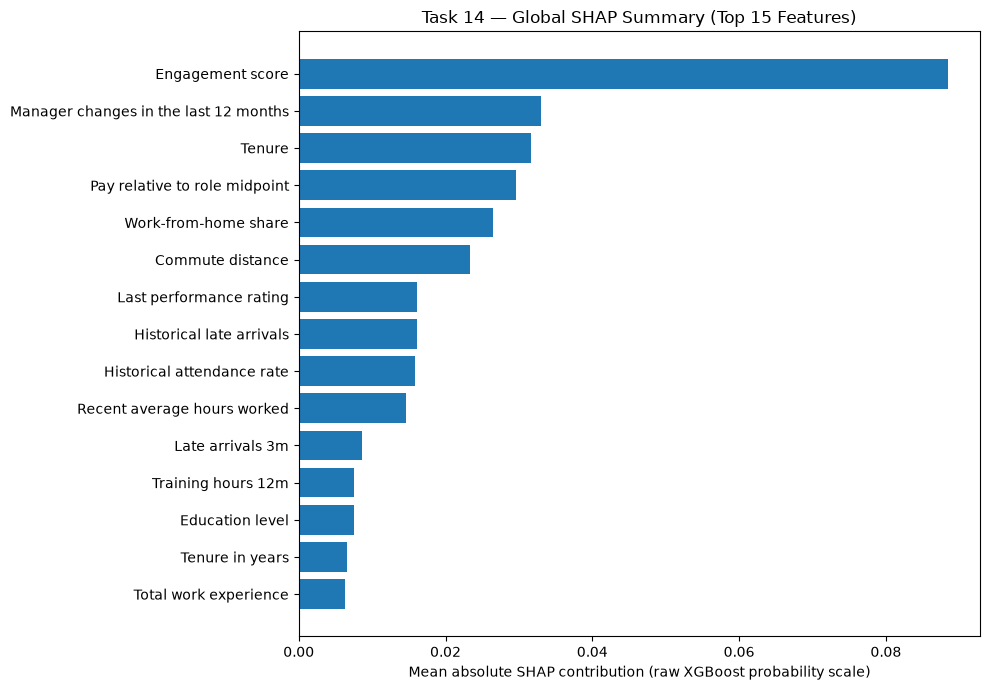

Top global SHAP features:


,feature,mean_abs_shap,feature_label
20,last_engagement_score,0.088400,Engagement score
21,manager_changes_12m,0.033063,Manager changes in the last 12 months
7,tenure_months,0.031672,Tenure
12,comp_ratio,0.029632,Pay relative to role midpoint
27,wfh_share_3m,0.026494,Work-from-home share
10,commute_distance_km,0.023282,Commute distance
19,last_performance_rating,0.016094,Last performance rating
32,late_count,0.016083,Historical late arrivals
31,attendance_rate,0.015812,Historical attendance rate
26,avg_hours_worked_3m,0.014611,Recent average hours worked


Output rows: 430
Output columns match sample: True
All employees have three reasons: True
Unique employees: 430


In [9]:
importance = pd.DataFrame({
    "feature": model_features,
    "mean_abs_shap": np.abs(grouped_shap).mean(axis=0),
})
importance["feature_label"] = importance["feature"].map(FEATURE_LABELS).fillna(
    importance["feature"].str.replace("_", " ").str.capitalize()
)
importance = importance.sort_values("mean_abs_shap", ascending=False)

top = importance.head(15).sort_values("mean_abs_shap")
plt.figure(figsize=(10, 7))
plt.barh(top["feature_label"], top["mean_abs_shap"])
plt.xlabel("Mean absolute SHAP contribution (raw XGBoost probability scale)")
plt.title("Task 14 — Global SHAP Summary (Top 15 Features)")
plt.tight_layout()
chart_path = EVIDENCE_DIR / "task14_shap_summary.png"
plt.savefig(chart_path, dpi=180, bbox_inches="tight")
plt.show()

print("Top global SHAP features:")
display(importance.head(10))
print("Output rows:", len(result))
print("Output columns match sample:", result.columns.tolist() == sample.columns.tolist())
print("All employees have three reasons:", result[["top_reason_1", "top_reason_2", "top_reason_3"]].notna().all().all())
print("Unique employees:", result["employee_id"].nunique())

In [10]:
summary = {
    "task": "Task 14 — Explain Every Person's Risk",
    "records_scored": int(len(result)),
    "unique_employees": int(result["employee_id"].nunique()),
    "model_version": metadata["version"],
    "risk_band_rule": "Task 4 risk_bands helper: High >= 90th percentile; Medium >= 70th percentile and below High; Low otherwise.",
    "risk_band_counts": {str(k): int(v) for k, v in result["risk_band"].value_counts().items()},
    "shap_method": "TreeSHAP interventional explanations for each of five XGBoost estimators inside CalibratedClassifierCV; one-hot contributions grouped to original model features.",
    "shap_background": "40 scoring-cohort rows sampled with random_state=42.",
    "shap_scope_limitation": "SHAP explains raw XGBoost estimators before sigmoid calibration; it is not an exact additive decomposition of final calibrated probability.",
    "additional_implementation_decisions": [
        "Reused Task 2 build_features() without inventing new model feature definitions.",
        "Reused Task 4 risk_bands() without changing the company thresholds.",
        "Selected the three largest positive grouped SHAP contributions for each employee.",
        "Used cautious association-based wording; reasons are not causal explanations."
    ],
    "outputs": {
        "risk_report": "reports/task14_attrition_risk_report.csv",
        "review_sample": "reports/task14_review_sample_10.csv",
        "shap_chart": "evidence/task14_shap_summary.png"
    },
    "limitations": [
        "No outcome labels are supplied for these 430 employees; this is not an accuracy evaluation.",
        "SHAP reasons are model associations, not causes or evidence of employee intent.",
        "Human review is required; scores must not independently determine employment decisions."
    ]
}
summary_path = REPORTS_DIR / "task14_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print("Saved:", summary_path)


Saved: /workspace/reports/task14_summary.json


## 8. Human review and responsible-use notes

Review all ten rows in `reports/task14_review_sample_10.csv`. Check whether the wording is understandable, non-judgmental, and supported by the feature values. In particular:
- Tenure or experience signals must not be presented as employee shortcomings; new joiners may naturally have shorter tenure.
- Attendance, overtime, pay, engagement, and manager-change signals can reflect circumstances outside an employee's control.
- A SHAP contribution describes the model's learned association, not a causal explanation or employee intent.
- A risk score must not independently determine hiring, promotion, compensation, discipline, or termination.

No outcome labels are included in the scoring file, so this task does not evaluate predictive accuracy on these 430 employees.

In [12]:
# Final validation: use the project-root-aware path configured in Cell 4.
report_path = REPORTS_DIR / "task14_attrition_risk_report.csv"
review_path = REPORTS_DIR / "task14_review_sample_10.csv"

if not report_path.exists():
    raise FileNotFoundError(
        f"Risk report not found at {report_path}. "
        "Run the export cell in Section 6 before this validation cell."
    )

df = pd.read_csv(REPORTS_DIR / "task14_attrition_risk_report.csv")
review_df = pd.read_csv(review_path) if review_path.exists() else None

print("Risk report:", report_path)
print("Total records:", len(df))
print("Unique employees:", df["employee_id"].nunique())

print("\\nRisk band distribution:")
print(df["risk_band"].value_counts().reindex(["High", "Medium", "Low"], fill_value=0))

reason_cols = ["top_reason_1", "top_reason_2", "top_reason_3"]
print("\\nMissing explanations:")
print(df[reason_cols].isna().sum())

print("\\nDuplicate employees:", df["employee_id"].duplicated().sum())
print("Columns:", df.columns.tolist())

assert len(df) == 430, f"Expected 430 rows; found {len(df)}"
assert df["employee_id"].nunique() == 430, "Expected 430 unique employees"
assert df[reason_cols].notna().all().all(), "At least one explanation is missing"
assert not df["employee_id"].duplicated().any(), "Duplicate employee IDs found"
assert df["risk_score_12m"].between(0, 1).all(), "Risk scores must be between 0 and 1"
assert set(df["risk_band"].dropna()).issubset({"High", "Medium", "Low"}), "Unexpected risk band"

if review_df is not None:
    assert len(review_df) == 10, f"Expected 10 review rows; found {len(review_df)}"
    print("\\nReview sample rows:", len(review_df))
else:
    print("\\nReview sample not found; rerun the Section 6 export cell.")

print("\\nAll Task 14 report validation checks passed.")


Risk report: /workspace/reports/task14_attrition_risk_report.csv
Total records: 430
Unique employees: 430
\nRisk band distribution:
risk_band
High       43
Medium     86
Low       301
Name: count, dtype: int64
\nMissing explanations:
top_reason_1    0
top_reason_2    0
top_reason_3    0
dtype: int64
\nDuplicate employees: 0
Columns: ['prediction_id', 'employee_id', 'department_id', 'as_of_date', 'risk_score_12m', 'risk_band', 'top_reason_1', 'top_reason_2', 'top_reason_3', 'model_version', 'model_note']
\nReview sample rows: 10
\nAll Task 14 report validation checks passed.


In [13]:
review_df = pd.read_csv(REPORTS_DIR / "task14_review_sample_10.csv")

for _, row in review_df.iterrows():
    print(f"\nEmployee: {row['employee_id']}")
    print(f"Risk score: {row['risk_score_12m']}")
    print(f"Risk band: {row['risk_band']}")
    print(f"Reason 1: {row['top_reason_1']}")
    print(f"Reason 2: {row['top_reason_2']}")
    print(f"Reason 3: {row['top_reason_3']}")
    print("-" * 80)


Employee: EMP-0403
Risk score: 0.424
Risk band: High
Reason 1: Engagement score (3.1/5) contributed to a higher model estimate.
Reason 2: Last performance rating (2.0/5) contributed to a higher model estimate.
Reason 3: Manager changes in the last 12 months (1.0) contributed to a higher model estimate.
--------------------------------------------------------------------------------

Employee: EMP-0599
Risk score: 0.417
Risk band: High
Reason 1: Engagement score (1.8/5) contributed to a higher model estimate.
Reason 2: Last performance rating (2.0/5) contributed to a higher model estimate.
Reason 3: Work-from-home share (2%) contributed to a higher model estimate.
--------------------------------------------------------------------------------

Employee: EMP-0481
Risk score: 0.408
Risk band: High
Reason 1: Engagement score (3.0/5) contributed to a higher model estimate.
Reason 2: Last performance rating (2.0/5) contributed to a higher model estimate.
Reason 3: Manager changes in the la